Cover experiment: can the cover image help? Sources: `cover/01_cover_pipeline.ipynb` and `02_cover_ablation.ipynb` (Colab), `cover/03_cover_merge.ipynb` → `cover/out/cover_merge.json`. Only valid covers are used: uploaded before chapter 3 and never changed (19,006 of 45,245 serials, almost all from 2020 on).

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
load = lambda rel: json.loads((ROOT / rel).read_text())
show = lambda rel, width=720: display(Image(filename=str(ROOT / rel), width=width))
pd.set_option("display.precision", 3)

In [2]:
cm = load("cover/out/cover_merge.json")
def table(rows):
    return pd.DataFrame(rows).set_index(["test_set", "model"])
by = pd.DataFrame(cm["test_hits_by_status"]).set_index("status")
by.columns = ["serials", "hits", "hit rate", "share of all hits"]
print("Where the 2023 hits are, by cover status:")
by.sort_values("hits", ascending=False)

Where the 2023 hits are, by cover status:


,serials,hits,hit rate,share of all hits
status,,,,
after_ch3,2551,544,0.213,0.671
valid,4507,253,0.056,0.312
no_custom_cover,995,12,0.012,0.015
image_changed,20,2,0.100,0.003
no_timestamp,2,0,0.000,0.000


Step 1, the Colab ablation: every model trained and tested on valid-cover serials; covers turned into vectors by four frozen image models.

In [3]:
ab = pd.read_csv(ROOT / "cover/out/ablation/ablation_results.csv")
ab = ab[ab["sample"] == "valid_cover"].set_index("model")[["test_auc", "test_recall_at_slots", "y2024_recall_at_slots"]]
ab.columns = ["2023 AUC", "2023 Recall@slots", "2024 Recall@slots"]
ab

,2023 AUC,2023 Recall@slots,2024 Recall@slots
model,,,
SAT,0.858,0.289,0.345
SAT+V_clip_l14,0.870,0.360,0.345
SAT+V_clip_b32,0.868,0.344,0.349
SAT+V_dinov2_base,0.858,0.328,0.323
SAT+V_resnet50,0.851,0.304,0.306
SAT+V_stats,0.858,0.289,0.349
SA,0.782,0.269,0.317
SA+V_clip_l14,0.808,0.324,0.330
V_clip_l14,0.739,0.206,0.176


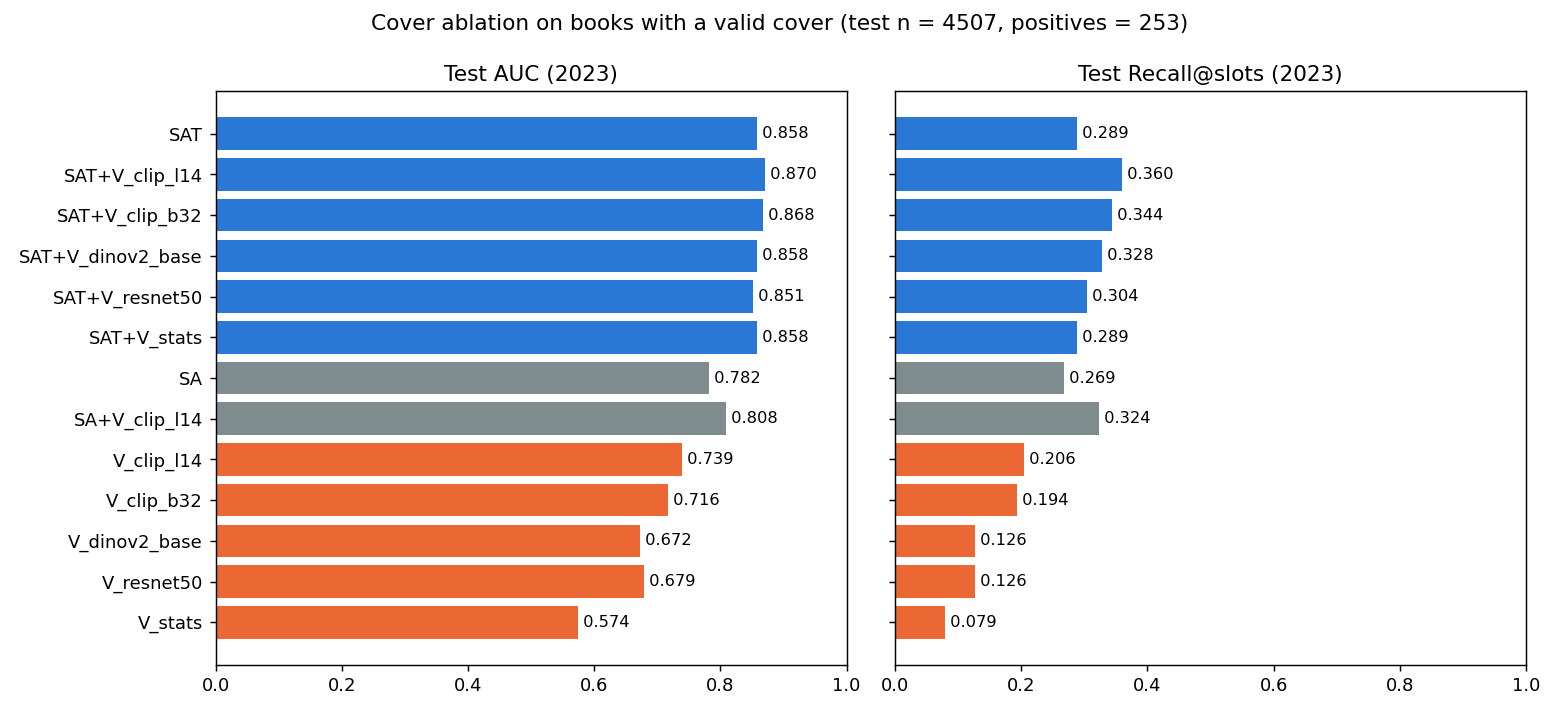

In [4]:
show("cover/out/ablation/ablation.png")

Step 2, was the baseline fair? The 0.289 baseline was trained on only about 7,000 valid-cover serials. The same S+A+T trained on all serials and scored on the same test serials gives 0.348.

In [5]:
table(cm["plan1_table"])

n  hits  \
test_set          model                                                    
2023 all          Rule: popular genres first                  8075   811   
                  S+A+T trained on valid-cover serials only   8075   811   
                  S+A+T trained on all serials (main)         8075   811   
2023 valid cover  Rule: popular genres first                  4507   253   
                  S+A+T trained on valid-cover serials only   4507   253   
                  S+A+T trained on all serials (main)         4507   253   
2023 other covers Rule: popular genres first                  3568   558   
                  S+A+T trained on valid-cover serials only   3568   558   
                  S+A+T trained on all serials (main)         3568   558   
2024 valid cover  Rule: popular genres first                  7335   461   
                  S+A+T trained on valid-cover serials only   7335   461   
                  S+A+T trained on all serials (main)         7335   461   
2024 all          Rule: popular genres first                 12165  1220   
                  S+A+T trained on valid-cover serials only  12165  1220   
                  S+A+T trained on all serials (main)        12165  1220   

                                                               auc  \
test_set          model                                              
2023 all          Rule: popular genres first                 0.743   
                  S+A+T trained on valid-cover serials only  0.859   
                  S+A+T trained on all serials (main)        0.887   
2023 valid cover  Rule: popular genres first                 0.747   
                  S+A+T trained on valid-cover serials only  0.858   
                  S+A+T trained on all serials (main)        0.878   
2023 other covers Rule: popular genres first                 0.727   
                  S+A+T trained on valid-cover serials only  0.857   
                  S+A+T trained on all serials (main)        0.888   
2024 valid cover  Rule: popular genres first                 0.777   
                  S+A+T trained on valid-cover serials only  0.865   
                  S+A+T trained on all serials (main)        0.876   
2024 all          Rule: popular genres first                 0.765   
                  S+A+T trained on valid-cover serials only  0.853   
                  S+A+T trained on all serials (main)        0.870   

                                                             recall_at_slots  \
test_set          model                                                        
2023 all          Rule: popular genres first                           0.261   
                  S+A+T trained on valid-cover serials only            0.408   
                  S+A+T trained on all serials (main)                  0.482   
2023 valid cover  Rule: popular genres first                           0.209   
                  S+A+T trained on valid-cover serials only            0.288   
                  S+A+T trained on all serials (main)                  0.348   
2023 other covers Rule: popular genres first                           0.330   
                  S+A+T trained on valid-cover serials only            0.514   
                  S+A+T trained on all serials (main)                  0.570   
2024 valid cover  Rule: popular genres first                           0.210   
                  S+A+T trained on valid-cover serials only            0.345   
                  S+A+T trained on all serials (main)                  0.351   
2024 all          Rule: popular genres first                           0.282   
                  S+A+T trained on valid-cover serials only            0.414   
                  S+A+T trained on all serials (main)                  0.453   

                                                             random  x_random  
test_set          model                                                        
2023 all          Rule: popular genres first                

Step 3, two-stage merge: the main model is trained on all serials; a cover adjustment is trained on valid-cover serials only, starting from the main score (fixed offset) with zero mean, so it cannot use "has a valid cover" as a signal. Serials without a valid cover keep the main score.

In [6]:
table(cm["plan2_table"])

n  hits  \
test_set         model                                                      
2023 all         Main model S+A+T (all serials)                8075   811   
                 Two-stage: main + cover adjustment            8075   811   
                 Diagnostic: adjustment centered per quarter   8075   811   
                 Control: shuffled covers                      8075   811   
2023 valid cover Main model S+A+T (all serials)                4507   253   
                 Two-stage: main + cover adjustment            4507   253   
                 Diagnostic: adjustment centered per quarter   4507   253   
                 Control: shuffled covers                      4507   253   
                 Control: S+A+T+V on valid covers only         4507   253   
2024 valid cover Main model S+A+T (all serials)                7335   461   
                 Two-stage: main + cover adjustment            7335   461   
                 Diagnostic: adjustment centered per quarter   7335   461   
                 Control: shuffled covers                      7335   461   
                 Control: S+A+T+V on valid covers only         7335   461   
2024 all         Main model S+A+T (all serials)               12165  1220   
                 Two-stage: main + cover adjustment           12165  1220   
                 Diagnostic: adjustment centered per quarter  12165  1220   
                 Control: shuffled covers                     12165  1220   

                                                                auc  \
test_set         model                                                
2023 all         Main model S+A+T (all serials)               0.887   
                 Two-stage: main + cover adjustment           0.884   
                 Diagnostic: adjustment centered per quarter  0.886   
                 Control: shuffled covers                     0.883   
2023 valid cover Main model S+A+T (all serials)               0.878   
                 Two-stage: main + cover adjustment           0.881   
                 Diagnostic: adjustment centered per quarter  0.881   
                 Control: shuffled covers                     0.868   
                 Control: S+A+T+V on valid covers only        0.870   
2024 valid cover Main model S+A+T (all serials)               0.876   
                 Two-stage: main + cover adjustment           0.878   
                 Diagnostic: adjustment centered per quarter  0.878   
                 Control: shuffled covers                     0.871   
                 Control: S+A+T+V on valid covers only        0.878   
2024 all         Main model S+A+T (all serials)               0.870   
                 Two-stage: main + cover adjustment           0.865   
                 Diagnostic: adjustment centered per quarter  0.869   
                 Control: shuffled covers                     0.867   

                                                              recall_at_slots  \
test_set         model                                                          
2023 all         Main model S+A+T (all serials)                         0.482   
                 Two-stage: main + cover adjustment                     0.481   
                 Diagnostic: adjustment centered per quarter            0.487   
                 Control: shuffled covers                               0.470   
2023 valid cover Main model S+A+T (all serials)                         0.348   
                 Two-stage: main + cover adjustment                     0.387   
                 Diagnostic: adjustment centered per quarter            0.387   
                 Control: shuffled covers                               0.324   
                 Control: S+A+T+V on valid covers only                  0.360   
2024 valid cover Main model S+A+T (all serials)                         0.351   
                 Two-stage: main + cover adjustment                     0.351   
                 Diagnostic: adjustment centered pe

In [7]:
pd.DataFrame({k: {"Recall@slots difference": v["recall_diff"], "95% CI": f"{v['recall_ci95'][0]:+.3f} to {v['recall_ci95'][1]:+.3f}",
                  "AUC difference": v["auc_diff"]} for k, v in cm["plan2_boot"].items()}).T

,Recall@slots difference,95% CI,AUC difference
two-stage minus main | 2023 valid cover,0.04,+0.012 to +0.084,0.003
two-stage minus main | 2023 all,-0.001,-0.017 to +0.011,-0.003
two-stage minus main | 2024 valid cover,0.0,-0.013 to +0.036,0.002
two-stage minus main | 2024 all,-0.021,-0.029 to -0.001,-0.005
centered minus main | 2023 all,0.005,-0.013 to +0.015,-0.001
centered minus main | 2024 all,-0.011,-0.021 to +0.006,-0.001
shuffled covers minus main | 2023 valid cover,-0.024,-0.051 to +0.024,-0.01
valid-cover-only S+A+T+V minus main | 2023 valid cover,0.012,-0.032 to +0.073,-0.008


Takeaways: covers carry a little real signal (+4.0 points among valid-cover serials in 2023, CI +1.2 to +8.4; shuffling the covers removes it) but none in 2024. Merged into the ranking of all serials they do not help (0.482 vs 0.481 in 2023; −2.1 in 2024) because the adjustment drifts upward on newer covers. Most of the ablation's +7.1 points came from a weak baseline: against a main model trained on all serials the gap is +1.2, not significant. The main model stays S+A+T; the most useful cover finding is the leakage one (covers changed after chapter 3 come with three times the hit rate).